### Verify setup before starting

In [3]:
from pathlib import Path
import pandas as pd
DATA_ROOT = Path("Task01_BrainTumour")
SPLIT_FILE = Path("assignment2_split.csv")
split_df = pd.read_csv(SPLIT_FILE)
assert len(split_df) == 484
assert set(split_df["split"]) == {"train", "validation", "test"}
for row in split_df.itertuples():
    assert (DATA_ROOT / row.image_relpath).exists()
    assert (DATA_ROOT / row.label_relpath).exists()
print(split_df["split"].value_counts())

split
train         338
test           73
validation     73
Name: count, dtype: int64


# A. Define the task and inspect the volumes

* State the input, output, unit of analysis and intended technical use. Distinguish a voxel, slice, volume and patient case

The input is going to be 4 channel volumes: Flair, T1-weighted, T1 contrast-enhanced and T2 weighted. Combined with depth, width and height, the input is a vector with dimensions (4, H, W, D). Our output is a binary segmentation mask for every voxel, meaning it will be of the dimension (H, W, D). The unit of analysis is going to be the voxel, as this is what we mask and what the modle is classifying. Additionally, we cannot share voxels from the same patient among our train, validation or test sets. The intended technical use is to build an end-to-end pipeline that educationally teaches and demonstrates how to do image segmentation for MRI. 

A voxel is a 3D pixel. A slice is a 2d sheet of voxels, so has Height, width and depth of 1 voxel unit. A volume will be a slice but with D voxels as depth. A patient case is 4 channels worth of volumes plus the segmentation label. 

------------------------------------------------------------------------------------------------------------------------------------------------

* Load at least three cases. Report array shape, channel order, affine matrix, orientation codes, voxel spacing and
label values.

In [2]:
#Get the first 3 training samples
'''
BRATS_001,train,imagesTr/BRATS_001.nii.gz,labelsTr/BRATS_001.nii.gz
BRATS_003,train,imagesTr/BRATS_003.nii.gz,labelsTr/BRATS_003.nii.gz
BRATS_004,train,imagesTr/BRATS_004.nii.gz,labelsTr/BRATS_004.nii.gz
'''

'''
From dataset.json:

"modality": { 
	 "0": "FLAIR", 
	 "1": "T1w", 
	 "2": "t1gd",
	 "3": "T2w"
 }
 This is the channel order above^

'''






#Import library that can read the data
import nibabel as nib
import numpy as np
DATASET_PATH = "Task01_BrainTumour/"
case_paths = [("imagesTr/BRATS_001.nii.gz", "labelsTr/BRATS_001.nii.gz"), ("imagesTr/BRATS_003.nii.gz","labelsTr/BRATS_003.nii.gz"), ("imagesTr/BRATS_004.nii.gz","labelsTr/BRATS_004.nii.gz")]
for patient in case_paths:
    volume_path, label_path = DATASET_PATH + patient[0], DATASET_PATH + patient[1]
    volume = nib.load(volume_path)
    label = nib.load(label_path)

    print(f"Image: {volume_path}")
    print(f"Label: {label_path}")

    print(f"Image shape: {volume.shape}")
    print(f"Label shape: {label.shape}")

    print(f"Image voxel spacing: {volume.header.get_zooms()}")
    print(f"Label voxel spacing: {label.header.get_zooms()}")

    print(f"Affine matrix: \n{volume.affine}")

    print(f"Orientation codes: {nib.aff2axcodes(volume.affine)}")

    label_data = label.get_fdata()
    print(f"Label values: {np.unique(label_data)}")


del label_data, label_path, volume, volume_path, label




Image: Task01_BrainTumour/imagesTr/BRATS_001.nii.gz
Label: Task01_BrainTumour/labelsTr/BRATS_001.nii.gz
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Image voxel spacing: (1.0, 1.0, 1.0, 1.0)
Label voxel spacing: (1.0, 1.0, 1.0)
Affine matrix: 
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Label values: [0. 1. 2. 3.]
Image: Task01_BrainTumour/imagesTr/BRATS_003.nii.gz
Label: Task01_BrainTumour/labelsTr/BRATS_003.nii.gz
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Image voxel spacing: (1.0, 1.0, 1.0, 1.0)
Label voxel spacing: (1.0, 1.0, 1.0)
Affine matrix: 
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Orientation codes: ('R', 'A', 'S')
Label values: [0. 1. 2. 3.]
Image: Task01_BrainTumour/imagesTr/BRATS_004.nii.gz
Label: Task01_BrainTumour/labelsTr/BRATS_004.nii.gz
Image shape: (240, 240, 155, 4)
Label shape: (240, 240, 155)
Image voxel spacing: (1.0, 1.0, 1.0, 1.0)
Label voxel spacing: (1.0

------------------------------------------------------------------------------------------------------------------------------------------------

* For one case, display FLAIR, T1, T1ce and T2 at the same physical location, plus the reference mask. 

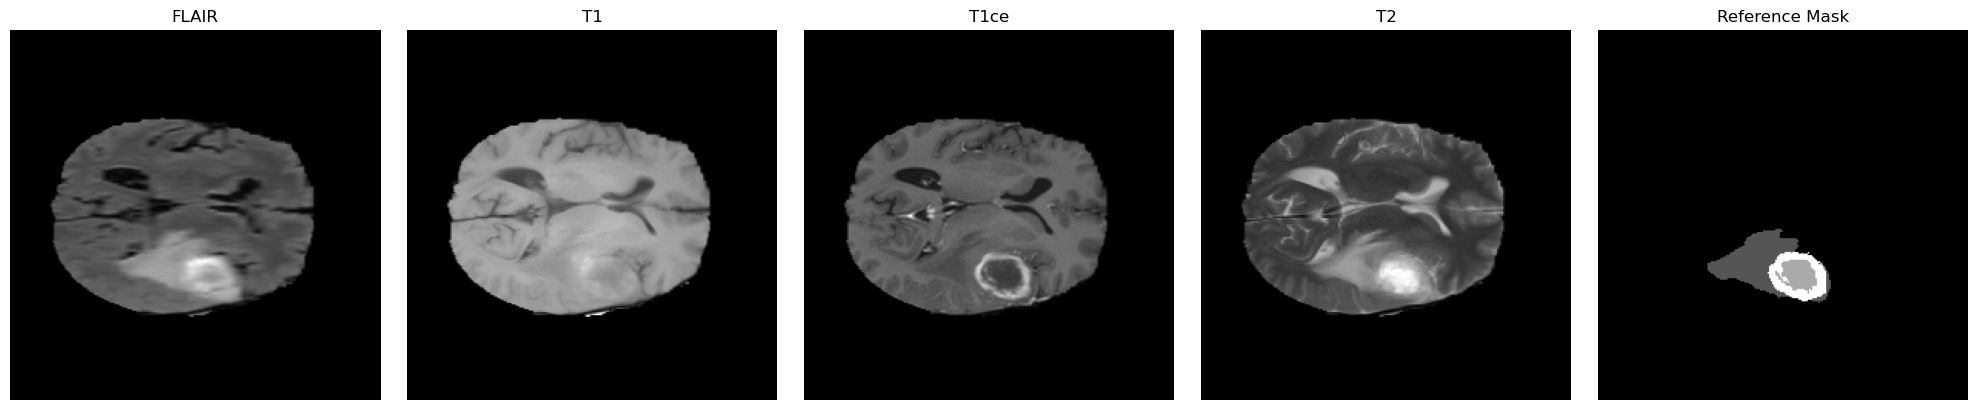

In [10]:
import matplotlib.pyplot as plt
case_1_volume = nib.load(DATASET_PATH + "imagesTr/BRATS_001.nii.gz")
case_1_label = nib.load(DATASET_PATH + "labelsTr/BRATS_001.nii.gz")

volume_data = case_1_volume.get_fdata()
label_data = case_1_label.get_fdata()

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
z = volume_data.shape[2] // 2 #middle slice

axes[0].set_title("FLAIR")
axes[1].set_title("T1")
axes[2].set_title("T1ce")
axes[3].set_title("T2")
axes[4].set_title("Reference Mask")

axes[0].imshow(volume_data[:, :, z, 0], cmap="gray")
axes[1].imshow(volume_data[:, :, z, 1], cmap="gray")
axes[2].imshow(volume_data[:, :, z, 2], cmap="gray")
axes[3].imshow(volume_data[:, :, z, 3], cmap="gray")
axes[4].imshow(label_data[:, :, z], cmap="gray")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()



------------------------------------------------------------------------------------------------------------------------------------------------

* Display the reference in axial, coronal and sagittal planes and explain why file-index order alone is insufficient
for spatial interpretation.

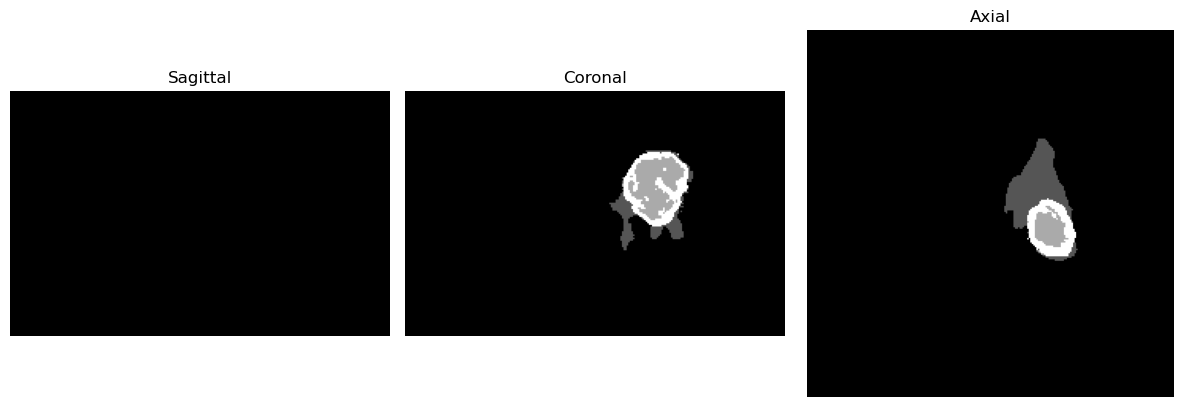

In [ ]:
'''
We had orientation codes (R, A, S), meaning [x::] = sagittal, [:y:] = coronal, [::z] = axial.
'''


fig, axes = plt.subplots(1, 3, figsize=(12, 4))



sagittal = label_data[(label_data.shape[0] // 2),:,:]
coronal = label_data[:,(label_data.shape[1] // 2),:]
axial = label_data[:,:,(label_data.shape[2] // 2)]

axes[0].imshow(sagittal.T, cmap="gray")
axes[0].set_title("Sagittal")

axes[1].imshow(coronal.T, cmap="gray")
axes[1].set_title("Coronal")

axes[2].imshow(axial.T, cmap="gray")
axes[2].set_title("Axial")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



'''
Spatial interpretation needs the affine matrix to map. Essentially:

[x, y, z] = A[i, j, k] where xyz is the spatial location and ijk are the array coordinates. As an array difference of 1 could correspond to any difference between real voxels.

'''
del sagittal, coronal, axial

------------------------------------------------------------------------------------------------------------------------------------------------

# B. Create a reproducible split

* Use the supplied assignment2 split.csv exactly. Do not create a slice-level or patch-level split. 

In [41]:
train_df = split_df[split_df["split"] == "train"]
validation_df   = split_df[split_df["split"] == "validation"]
test_df  = split_df[split_df["split"] == "test"]

------------------------------------------------------------------------------------------------------------------------------------------------

* Verify that every listed image and label exists and that case identifiers are disjoint across train, validation and
test.

In [42]:
#First check every listed image and label exists
for _, row in split_df.iterrows():

    image_path = Path(DATASET_PATH + row["image_relpath"])
    label_path = Path(DATASET_PATH + row["label_relpath"])

    assert image_path.exists()
    assert label_path.exists()

#Now check no patient leakage
train_set = set(split_df[split_df["split"] == "train"]["case_id"])
validation_set = set(split_df[split_df["split"] == "validation"]["case_id"])
test_set = set(split_df[split_df["split"] == "test"]["case_id"])

assert train_set.isdisjoint(test_set)
assert train_set.isdisjoint(validation_set)
assert validation_set.isdisjoint(test_set)

del train_set, validation_set, test_set

------------------------------------------------------------------------------------------------------------------------------------------------

* Report case counts and the distribution of reference tumor volume in each split. Keep the test labels unused
until final evaluation.

Train case count: 338
Validation case count: 73
Test case count: 73


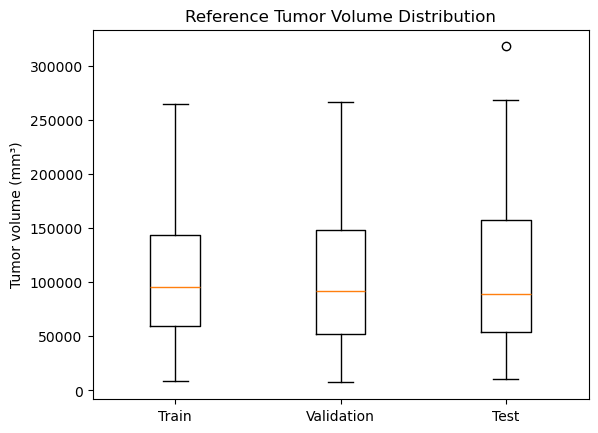

In [48]:
#First report case counts

print(f"Train case count: {len(train_df)}")
print(f"Validation case count: {len(validation_df)}")
print(f"Test case count: {len(test_df)}")

#Then describe distribution of reference tumor volume per split

tumor_volumes = list()

for _, row in split_df.iterrows():

    label = nib.load(DATASET_PATH + row["label_relpath"])
    label_data = label.get_fdata()

    tumor_voxels = np.sum(label_data > 0) #Everything becomes either true or false after label_data > 0, hence summing here gives voxel count that has tumor

    voxel_volume = np.prod(label.header.get_zooms()[:3]) #Get the actual voxel dimension reference and multiply them together to get volume 1 voxel takes up

    tumor_volume = tumor_voxels * voxel_volume

    tumor_volumes.append((row["split"],tumor_volume))


train_volumes = [v for split, v in tumor_volumes if split == "train"]
val_volumes   = [v for split, v in tumor_volumes if split == "validation"]
test_volumes  = [v for split, v in tumor_volumes if split == "test"]

plt.boxplot([train_volumes, val_volumes, test_volumes])
plt.xticks([1, 2, 3], ["Train", "Validation", "Test"])
plt.ylabel("Tumor volume (mm³)")
plt.title("Reference Tumor Volume Distribution")
plt.show()

------------------------------------------------------------------------------------------------------------------------------------------------

# C. Preprocess MRI and labels safely

* Verify geometry across all four channels and the label. If resampling is needed, define one target grid and
document it.

In [ ]:
for _, row in split_df.iterrows():

    image = nib.load(DATASET_PATH + row["image_relpath"])
    label = nib.load(DATASET_PATH + row["label_relpath"])

    assert image.shape[:3] == label.shape

    assert np.allclose(image.header.get_zooms()[:3], label.header.get_zooms()[:3])

    assert np.allclose(image.affine, label.affine)
print("All MRI volumes and labels have matching geometry.")

All MRI volumes and labels have matching geometry.


------------------------------------------------------------------------------------------------------------------------------------------------

* Use linear interpolation for MRI and nearest-neighbour interpolation for labels. Demonstrate that label values
remain valid.

In [ ]:
'''
I do not exactly know WHY we need to interpolate anything? Given that the geometries match up. In any case, I will make functions here that can do it in case for the future.
'''
from scipy.ndimage import zoom

def resample_mri(data, zoom_factor):
    return zoom(data, (*zoom_factor, 1), order=1) #Example usage is zoom_factor = (0.5, 0.5, 0.5). (240, 240, 155, 4) -> (120, 120, 78, 4)

def resample_label(data, zoom_factor):
    return zoom(data, zoom_factor, order=0)

example_array = np.array([
    [0, 0, 1, 2],
    [2, 3, 0, 1],
    [2, 1, 0, 3],
    [0, 1, 0, 0],

])
resampled = resample_label(example_array, (0.5, 0.5))
print("Original values:", np.unique(example_array))
print("Resampled values:", np.unique(resampled))
#See how they are a subset



del example_array, resampled




Original values: [0 1 2 3]
Resampled values: [0 2]


------------------------------------------------------------------------------------------------------------------------------------------------

* Normalize each MRI channel using statistics from non-zero brain voxels, not the zero-padded background. Report
the resulting mean and standard deviation. 

In [57]:
means = [0, 0, 0, 0]
stds = [0, 0, 0, 0]
counts = [0, 0, 0, 0]

for _, row in train_df.iterrows():

    image = nib.load(DATASET_PATH + row["image_relpath"])
    image_data = image.get_fdata()

    for channel in range(4):

        channel_data = image_data[:, :, :, channel]

        brain_voxels = channel_data[channel_data != 0]

        means[channel] += np.sum(brain_voxels)
        stds[channel] += np.sum(brain_voxels ** 2)
        counts[channel] += len(brain_voxels)

for channel in range(4):
    means[channel] /= counts[channel]
    stds[channel] = np.sqrt(stds[channel] / counts[channel] - means[channel] ** 2)


channels = ["FLAIR", "T1", "T1ce", "T2"]



Channel: FLAIR
 mean: 464.9858864745449
 std: 270.2428220084918
Channel: T1
 mean: 613.3651687800044
 std: 331.28203722243865
Channel: T1ce
 mean: 616.2871196537117
 std: 391.1857794860021
Channel: T2
 mean: 489.1851223394134
 std: 287.796171497187


Continuation below as the above takes a minute to run

In [ ]:
for channel in range(4):
    print(f"Channel: {channels[channel]}\n mean: {means[channel]}\n std: {stds[channel]}")

#Now do the normalising
def normalise(image):
    normalised = np.zeros_like(image)

    for channel in range(4):
        normalised[:,:,:,channel] = np.where(image[:,:,:,channel] == 0, (image[:,:,:,channel] - means[channel]) / stds[channel])

    return normalised

'''Note just planning ahead the actual normalising happens in the dataset and dataloader'''



Channel: FLAIR
 mean: 464.9858864745449
 std: 270.2428220084918
Channel: T1
 mean: 613.3651687800044
 std: 331.28203722243865
Channel: T1ce
 mean: 616.2871196537117
 std: 391.1857794860021
Channel: T2
 mean: 489.1851223394134
 std: 287.796171497187


------------------------------------------------------------------------------------------------------------------------------------------------

* Crop or pad consistently and apply safe training-only augmentation. Show one paired before/after example and
justify the transforms.

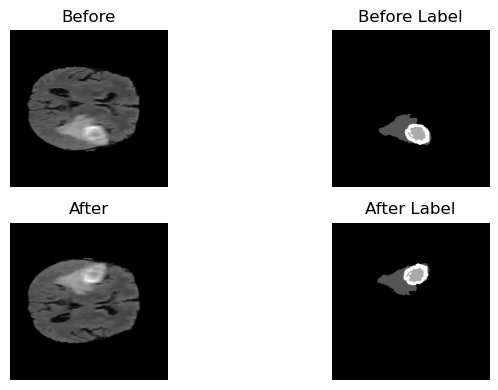

In [12]:
from scipy.ndimage import rotate
class RandomFlip:

    def __init__(self, probability=0.5):
        self.probability = probability

    def __call__(self, image, label):

        if np.random.random() < self.probability:
            image = np.flip(image, axis=0).copy() #Sagittal flip
            label = np.flip(label, axis=0).copy() #Also flip label to match

        return image, label

class Rotation:

    def __init__(self, degrees=10):
            self.degrees = degrees
    
    def __call__(self, image, label):
    
        angle = np.random.uniform(-self.degrees, self.degrees)

        for channel in range(4):

            image[:, :, :, channel] = rotate(image[:, :, :, channel],angle,reshape=False,order=1)

        label = rotate(label, angle, reshape=False, order=0)
        return image, label



#Show a before and after

case_1_volume = nib.load(DATASET_PATH + "imagesTr/BRATS_001.nii.gz")
case_1_label = nib.load(DATASET_PATH + "labelsTr/BRATS_001.nii.gz")

data = case_1_volume.get_fdata()
label = case_1_label.get_fdata()

slice = data.shape[2] // 2

after_image, after_label = Rotation(10)(data.copy(), label.copy())
after_image, after_label = RandomFlip(0.25)(after_image, after_label)

before_image = data[:, :, data.shape[2] // 2, 0]  
before_label = label[:, :, data.shape[2] // 2]

after_image = after_image[:, :, data.shape[2] // 2, 0]
after_label = after_label[:, :, data.shape[2] // 2]

plt.figure(figsize=(8, 4))

plt.subplot(2, 2, 1)
plt.imshow(before_image, cmap="gray")
plt.title("Before")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(before_label, cmap="gray")
plt.title("Before Label")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(after_image, cmap="gray")
plt.title("After")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(after_label, cmap="gray")
plt.title("After Label")
plt.axis("off")

plt.tight_layout()
plt.show()






------------------------------------------------------------------------------------------------------------------------------------------------

# D. Implement patch-based volumetric training

* Implement a PyTorch Dataset and DataLoader returning tensors shaped [C, D, H, W ] and binary masks shaped
[1, D, H, W ]. Print and verify one batch. 

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class BrainTumorDataset(Dataset):

    def __init__(self, dataframe):
        pass

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        pass

------------------------------------------------------------------------------------------------------------------------------------------------

* Build a lightweight 3D U-Net or equivalent fully convolutional 3D model. Report input channels, output channels,
parameter count and patch size. 

------------------------------------------------------------------------------------------------------------------------------------------------

* Train first with uniform random patches. State the loss, optimizer, learning rate, epoch/iteration budget and
random seed.

------------------------------------------------------------------------------------------------------------------------------------------------

* Train the same model with tumor-aware patch sampling. Keep initialization and training budget controlled.
Report the fraction of sampled patches containing tumor for both samplers. 

------------------------------------------------------------------------------------------------------------------------------------------------

* Plot training and validation loss and validation Dice. Identify underfitting, instability or overfitting without
using test results for selection. 

------------------------------------------------------------------------------------------------------------------------------------------------

# E. Controlled sampling comparison

# F. Reconstruct and evaluate full volumes

# G. Three-plane error analysis and limitations